# 12 — Base única com 64 contratos e prova de viabilidade da previsão inicial

## Mensagem principal

Em vez de descartar contratos que ainda não terminaram, este notebook mantém **todos os contratos selecionados** e os organiza em três grupos:

1. **Concluídos com target conhecido**
2. **Em andamento — censurados**
3. **Suspensos/paralisados**

A ideia é simples:

- contratos concluídos informam **quanto tempo realmente levaram**;
- contratos em andamento informam que **ainda não concluíram até a data de corte**;
- contratos suspensos/paralisados permanecem no dataset, mas não são misturados ao processo normal de conclusão.

Isso permite construir uma previsão inicial **agora**, sem transformar contratos em andamento em falsos "sem atraso".

## O que queremos demonstrar

Este notebook não tenta provar que o modelo já está pronto para produção.

Ele tenta demonstrar três coisas:

- a previsão inicial é **estatisticamente factível**;
- existe um desenho de target que usa corretamente a realidade atual;
- o modelo tende a melhorar quando mais contratos forem concluídos e quando forem adicionadas features de execução historicamente seguras.

Para facilitar a explicação a um colega, o notebook usa poucas features e um modelo simples de sobrevivência.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.stats import norm

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import TweedieRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_tweedie_deviance,
)

from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

DATA_CORTE = pd.Timestamp("2026-10-14")
RANDOM_STATE = 42

OUTPUT_DIR = Path("/mnt/data/12_base_64_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Data de corte:", DATA_CORTE.date())
print("Pasta de saída:", OUTPUT_DIR)

Data de corte: 2026-10-14
Pasta de saída: \mnt\data\12_base_64_outputs


## 1. Carregar os arquivos

In [17]:
def pastas_raw_candidatas():
    atual = Path.cwd().resolve()
    candidatas = [
        raiz / "data" / "raw"
        for raiz in (atual, *atual.parents)
    ]
    candidatas.append(Path("/mnt/data/raw"))
    return candidatas


def localizar(*nomes):
    pastas = pastas_raw_candidatas()
    for pasta in pastas:
        for nome in nomes:
            caminho = pasta / nome
            if caminho.is_file():
                return caminho.resolve()
    raise FileNotFoundError(
        f"Arquivo(s) não encontrado(s): {', '.join(nomes)}. "
        f"Diretório atual: {Path.cwd().resolve()}. "
        f"Pastas verificadas: {', '.join(str(p) for p in pastas)}"
    )


PATH_CONTRATOS = localizar(
    "contratos_com_conclusao_andamento.csv"
)

PATH_PARCELAS = localizar(
    "vw_bi_parcelas(1).csv",
    "vw_bi_parcelas.csv",
)

PATH_ADITIVOS_PRAZO = localizar(
    "vw_taditivoprazo(1).csv",
    "vw_taditivoprazo.csv",
)

PATH_ADITIVOS_VALOR = localizar(
    "vw_taditivovalor(1).csv",
    "vw_taditivovalor.csv",
)

PATH_LIBERACOES = localizar(
    "vw_tparcela_liberacao(1).csv",
    "vw_tparcela_liberacao.csv",
)


contratos = pd.read_csv(
    PATH_CONTRATOS,
    encoding="utf-8-sig",
    low_memory=False,
)

parcelas = pd.read_csv(
    PATH_PARCELAS,
    encoding="utf-8-sig",
    low_memory=False,
)

aditivos_prazo = pd.read_csv(
    PATH_ADITIVOS_PRAZO,
    encoding="utf-8-sig",
    low_memory=False,
)

aditivos_valor = pd.read_csv(
    PATH_ADITIVOS_VALOR,
    encoding="utf-8-sig",
    low_memory=False,
)

liberacoes = pd.read_csv(
    PATH_LIBERACOES,
    encoding="utf-8-sig",
    low_memory=False,
)

print("Contratos:", contratos.shape)
print("Parcelas:", parcelas.shape)
print("Aditivos prazo:", aditivos_prazo.shape)
print("Aditivos valor:", aditivos_valor.shape)
print("Liberações:", liberacoes.shape)

Contratos: (64, 10)
Parcelas: (13010, 11)
Aditivos prazo: (245, 10)
Aditivos valor: (271, 10)
Liberações: (11918, 8)


## 2. Preparar datas e restringir as tabelas auxiliares aos contratos selecionados

In [18]:
# Datas da tabela principal
for coluna in [
    "data_os",
    "data_termino_original",
    "data_termino_vigente_final",
    "data_conclusao_definitiva",
]:
    contratos[coluna] = pd.to_datetime(
        contratos[coluna],
        errors="coerce",
    )

# Datas dos aditivos de prazo
for coluna in [
    "Data_termino_anterior",
    "Data_termino_nova",
    "Data_assinatura_ta_prazo",
]:
    aditivos_prazo[coluna] = pd.to_datetime(
        aditivos_prazo[coluna],
        errors="coerce",
    )

# Datas dos aditivos de valor
aditivos_valor["Data_assinatura_TA_valor"] = pd.to_datetime(
    aditivos_valor["Data_assinatura_TA_valor"],
    errors="coerce",
)

# Datas das parcelas
for coluna in [
    "data_prevista_parcela",
    "data_efetiva",
    "data_liberacao",
]:
    parcelas[coluna] = pd.to_datetime(
        parcelas[coluna],
        errors="coerce",
    )

# Datas das liberações
for coluna in [
    "Data_efet_conclusao",
    "Data_liberação",
]:
    liberacoes[coluna] = pd.to_datetime(
        liberacoes[coluna],
        errors="coerce",
    )


ids = set(
    contratos["id_contrato"]
)

parcelas = parcelas[
    parcelas["id_contrato"].isin(ids)
].copy()

aditivos_prazo = aditivos_prazo[
    aditivos_prazo["idContrato"].isin(ids)
].copy()

aditivos_valor = aditivos_valor[
    aditivos_valor["idContrato"].isin(ids)
].copy()

liberacoes = liberacoes[
    liberacoes["id_Contrato"].isin(ids)
].copy()

assert contratos["id_contrato"].is_unique

print("Contratos selecionados:", len(contratos))

Contratos selecionados: 64


# Parte A — Construção do dataset

## 3. Criar os três grupos

A classificação usa o **desfecho observado**, e não apenas o texto do status.

Por isso, se um contrato possui `data_conclusao_definitiva` e `atraso_definitivo_dias`, ele é tratado como **concluído com target**, mesmo que o status cadastral ainda esteja desatualizado.

Isso evita perder informação válida por atraso de atualização cadastral.

In [19]:
df = contratos.copy()

tem_target = (
    df["data_conclusao_definitiva"].notna()
    & df["atraso_definitivo_dias"].notna()
)

status_suspenso = (
    df["status_final_controle"]
    .astype(str)
    .str.upper()
    .str.contains(
        "SUSPENSO|PARALISADO",
        regex=True,
    )
)

df["grupo_modelagem"] = np.select(
    [
        tem_target,
        status_suspenso,
    ],
    [
        "CONCLUIDO_COM_TARGET",
        "SUSPENSO_PARALISADO",
    ],
    default="EM_ANDAMENTO_CENSURADO",
)

# Ajuda a localizar registros cujo status cadastral ainda não acompanha
# a conclusão definitiva.
df["flag_status_desatualizado"] = (
    df["grupo_modelagem"].eq(
        "CONCLUIDO_COM_TARGET"
    )
    & ~df["status_final_controle"].eq(
        "CONCLUÍDO"
    )
).astype(int)

resumo_grupos = (
    df["grupo_modelagem"]
    .value_counts()
    .rename_axis("grupo")
    .reset_index(name="contratos")
)

display(resumo_grupos)

print(
    "Contratos concluídos com status cadastral diferente de CONCLUÍDO:",
    int(df["flag_status_desatualizado"].sum()),
)

,grupo,contratos
0,CONCLUIDO_COM_TARGET,50
1,EM_ANDAMENTO_CENSURADO,13
2,SUSPENSO_PARALISADO,1


Contratos concluídos com status cadastral diferente de CONCLUÍDO: 2


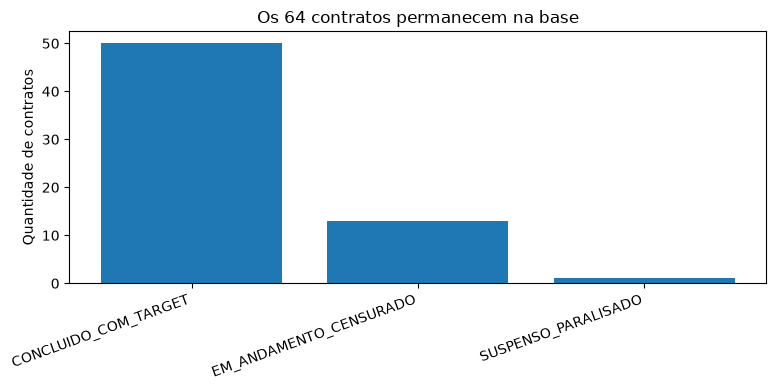

In [20]:
plt.figure(figsize=(8, 4))

plt.bar(
    resumo_grupos["grupo"],
    resumo_grupos["contratos"],
)

plt.ylabel("Quantidade de contratos")
plt.title("Os 64 contratos permanecem na base")

plt.xticks(
    rotation=20,
    ha="right",
)

plt.tight_layout()
plt.show()

## 4. Target principal: tempo até conclusão com censura

Para esta realidade, o target mais apropriado não é apenas `dias de atraso`.

Usamos o par:

- `tempo_observado_dias`
- `evento_conclusao`

### Interpretação

**Contrato concluído**

`tempo_observado_dias = data_conclusao - data_os`

e:

`evento_conclusao = 1`

**Contrato em andamento**

`tempo_observado_dias = data_corte - data_os`

e:

`evento_conclusao = 0`

Assim, o modelo sabe que aquele contrato já durou pelo menos esse tempo, sem supor quanto ainda vai durar.

In [21]:
# Evento de conclusão observado
df["evento_conclusao"] = (
    df["grupo_modelagem"].eq(
        "CONCLUIDO_COM_TARGET"
    )
).astype(int)

# Fim da observação:
# conclusão para eventos; data de corte para os demais.
df["data_fim_observacao"] = (
    df["data_conclusao_definitiva"]
    .where(
        df["evento_conclusao"].eq(1),
        DATA_CORTE,
    )
)

df["tempo_observado_dias"] = (
    df["data_fim_observacao"]
    - df["data_os"]
).dt.days

# O target de atraso em dias continua existindo,
# mas somente quando o desfecho é conhecido.
df["target_atraso_dias"] = (
    df["atraso_definitivo_dias"]
    .where(
        df["grupo_modelagem"].eq(
            "CONCLUIDO_COM_TARGET"
        )
    )
)

df["target_atraso_binario"] = np.where(
    df["target_atraso_dias"].notna(),
    (
        df["target_atraso_dias"] > 0
    ).astype(float),
    np.nan,
)

# O suspenso/paralisado fica na base, mas não é misturado
# ao processo normal de conclusão.
df["flag_apto_modelo_survival"] = (
    ~df["grupo_modelagem"].eq(
        "SUSPENSO_PARALISADO"
    )
).astype(int)

display(
    df[
        [
            "id_contrato",
            "grupo_modelagem",
            "data_os",
            "data_fim_observacao",
            "tempo_observado_dias",
            "evento_conclusao",
            "target_atraso_dias",
            "flag_apto_modelo_survival",
        ]
    ].head(10)
)

,id_contrato,grupo_modelagem,data_os,data_fim_observacao,tempo_observado_dias,evento_conclusao,target_atraso_dias,flag_apto_modelo_survival
0,11,CONCLUIDO_COM_TARGET,2019-07-24,2020-01-15,175,1,25.0,1
1,12,CONCLUIDO_COM_TARGET,2018-03-22,2018-11-06,229,1,139.0,1
2,18,CONCLUIDO_COM_TARGET,2019-09-11,2020-02-08,150,1,0.0,1
3,29,CONCLUIDO_COM_TARGET,2019-01-29,2020-07-06,524,1,106.0,1
4,30,CONCLUIDO_COM_TARGET,2020-01-07,2020-04-06,90,1,0.0,1
5,31,CONCLUIDO_COM_TARGET,2019-07-11,2020-02-06,210,1,30.0,1
6,32,CONCLUIDO_COM_TARGET,2020-01-27,2020-06-25,150,1,0.0,1
7,33,CONCLUIDO_COM_TARGET,2018-10-08,2020-10-27,750,1,0.0,1
8,46,CONCLUIDO_COM_TARGET,2019-04-25,2020-02-17,298,1,28.0,1
9,47,CONCLUIDO_COM_TARGET,2019-04-24,2019-12-02,222,1,12.0,1


## 5. Reconstruir o prazo vigente conhecido na observação

Para estimar risco de atraso dos contratos em andamento, precisamos comparar o tempo de conclusão com o prazo que está vigente.

Regra:

- começa com o prazo original;
- aplica o último aditivo de prazo assinado até a data observada;
- nunca usa um aditivo assinado depois do ponto de observação.

In [22]:
df["data_termino_original_calc"] = (
    df["data_os"]
    + pd.to_timedelta(
        df["prazo_original_dias"],
        unit="D",
    )
)


def prazo_vigente_no_corte(row):

    contrato = row["id_contrato"]
    cutoff = row["data_fim_observacao"]

    ad = aditivos_prazo[
        aditivos_prazo["idContrato"].eq(
            contrato
        )
        & aditivos_prazo[
            "Data_assinatura_ta_prazo"
        ].notna()
        & aditivos_prazo[
            "Data_termino_nova"
        ].notna()
        & (
            aditivos_prazo[
                "Data_assinatura_ta_prazo"
            ]
            <= cutoff
        )
    ].sort_values(
        [
            "Data_assinatura_ta_prazo",
            "Data_termino_nova",
        ]
    )

    if len(ad):
        return ad.iloc[-1][
            "Data_termino_nova"
        ]

    return row[
        "data_termino_original_calc"
    ]


df["data_termino_vigente_observada"] = (
    df.apply(
        prazo_vigente_no_corte,
        axis=1,
    )
)

df["prazo_vigente_observado_dias"] = (
    df["data_termino_vigente_observada"]
    - df["data_os"]
).dt.days

df["dias_ate_prazo_na_data_corte"] = (
    df["data_termino_vigente_observada"]
    - DATA_CORTE
).dt.days

print(
    "Prazos vigentes reconstruídos:",
    int(
        df[
            "data_termino_vigente_observada"
        ].notna().sum()
    ),
    "de",
    len(df),
)

Prazos vigentes reconstruídos: 64 de 64


## 6. Features iniciais

Para provar viabilidade sem exagerar a capacidade do modelo, começamos com poucas informações que existem no início do contrato:

- prazo original;
- classificação da obra;
- quantidade de parcelas originais.

A quantidade de parcelas é tratada como feature candidata porque normalmente pertence ao planejamento inicial. Se houver dúvida sobre versionamento histórico dessa informação, o notebook também avalia modelos sem ela.

In [23]:
qtd_parcelas_originais = (
    parcelas[
        parcelas["tipo_de_parcela"].eq(
            "Serviços Originais"
        )
    ]
    .groupby("id_contrato")
    ["id_parcela"]
    .nunique()
    .rename(
        "qtd_parcelas_originais"
    )
)

df = df.merge(
    qtd_parcelas_originais,
    left_on="id_contrato",
    right_index=True,
    how="left",
)

df["log_prazo_original"] = np.log1p(
    df["prazo_original_dias"]
)

df["log_qtd_parcelas_originais"] = np.log1p(
    df["qtd_parcelas_originais"]
)

display(
    df[
        [
            "prazo_original_dias",
            "classificacao_contrato",
            "qtd_parcelas_originais",
        ]
    ].describe(
        include="all"
    ).T
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
prazo_original_dias,64.0,NaN,NaN,NaN,356.25,335.537948,60.0,112.5,180.0,600.0,1260.0
classificacao_contrato,64,5,Reforma Parcial,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qtd_parcelas_originais,62.0,NaN,NaN,NaN,13.822581,12.96973,1.0,4.0,8.5,20.75,50.0


## 7. Guardar também sinais de execução para a próxima fase

Essas colunas **não entram na previsão inicial**.

Elas são mantidas no dataset porque serão úteis na próxima evolução: previsões atualizadas durante a obra.

A regra é sempre usar somente eventos observados até `data_fim_observacao`.

In [24]:
exec_rows = []

for _, row in df.iterrows():

    contrato = row["id_contrato"]
    cutoff = row["data_fim_observacao"]

    ap = aditivos_prazo[
        aditivos_prazo["idContrato"].eq(
            contrato
        )
        & aditivos_prazo[
            "Data_assinatura_ta_prazo"
        ].notna()
        & (
            aditivos_prazo[
                "Data_assinatura_ta_prazo"
            ] <= cutoff
        )
    ]

    av = aditivos_valor[
        aditivos_valor["idContrato"].eq(
            contrato
        )
        & aditivos_valor[
            "Data_assinatura_TA_valor"
        ].notna()
        & (
            aditivos_valor[
                "Data_assinatura_TA_valor"
            ] <= cutoff
        )
    ]

    pp = parcelas[
        parcelas["id_contrato"].eq(
            contrato
        )
        & parcelas[
            "data_efetiva"
        ].notna()
        & (
            parcelas[
                "data_efetiva"
            ] <= cutoff
        )
    ]

    ll = liberacoes[
        liberacoes["id_Contrato"].eq(
            contrato
        )
        & liberacoes[
            "Data_liberação"
        ].notna()
        & (
            liberacoes[
                "Data_liberação"
            ] <= cutoff
        )
    ]

    exec_rows.append({
        "id_contrato": contrato,
        "qtd_aditivos_prazo_observados": len(ap),
        "qtd_aditivos_valor_observados": len(av),
        "qtd_parcelas_concluidas_observadas": (
            pp["id_parcela"].nunique()
        ),
        "qtd_liberacoes_observadas": len(ll),
    })

execucao = pd.DataFrame(
    exec_rows
)

df = df.merge(
    execucao,
    on="id_contrato",
    how="left",
)

## 8. Visualizar o que já temos e o que ainda será aprendido

Eventos de conclusão disponíveis hoje: 50
Contratos em andamento que podem virar novos eventos: 13
Suspensos/paralisados mantidos separadamente: 1
Crescimento potencial dos eventos observados: +26.0%


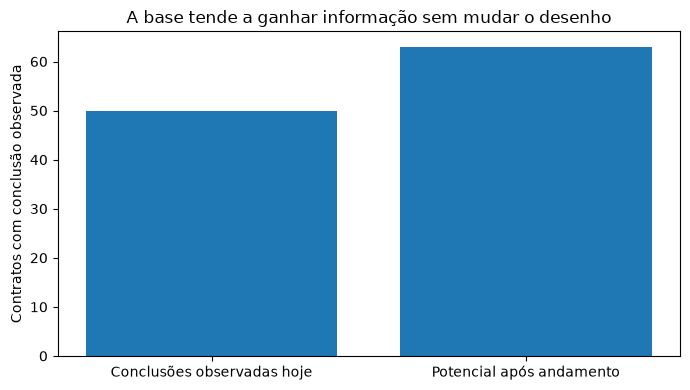

In [25]:
n_concluidos = int(
    df[
        "grupo_modelagem"
    ].eq(
        "CONCLUIDO_COM_TARGET"
    ).sum()
)

n_andamento = int(
    df[
        "grupo_modelagem"
    ].eq(
        "EM_ANDAMENTO_CENSURADO"
    ).sum()
)

n_suspensos = int(
    df[
        "grupo_modelagem"
    ].eq(
        "SUSPENSO_PARALISADO"
    ).sum()
)

crescimento_potencial = (
    100
    * n_andamento
    / max(
        n_concluidos,
        1,
    )
)

print(
    f"Eventos de conclusão disponíveis hoje: {n_concluidos}"
)

print(
    f"Contratos em andamento que podem virar novos eventos: {n_andamento}"
)

print(
    f"Suspensos/paralisados mantidos separadamente: {n_suspensos}"
)

print(
    f"Crescimento potencial dos eventos observados: +{crescimento_potencial:.1f}%"
)

plt.figure(figsize=(7, 4))

plt.bar(
    [
        "Conclusões observadas hoje",
        "Potencial após andamento",
    ],
    [
        n_concluidos,
        n_concluidos + n_andamento,
    ],
)

plt.ylabel("Contratos com conclusão observada")
plt.title("A base tende a ganhar informação sem mudar o desenho")

plt.tight_layout()
plt.show()

# Parte B — Prova de viabilidade da previsão inicial

## 9. Por que usar um modelo de sobrevivência?

Uma regressão comum exige saber o resultado final de todas as linhas.

O modelo de sobrevivência aceita:

- eventos concluídos;
- observações ainda censuradas.

Assim, o contrato em andamento **contribui para o aprendizado sem receber um target inventado**.

Para manter o notebook autocontido, usamos um **AFT Log-Normal regularizado**.

In [26]:
class LogNormalAFT:

    def __init__(
        self,
        alpha=100.0,
    ):
        self.alpha = alpha

    def fit(
        self,
        X,
        tempo,
        evento,
    ):
        X = np.asarray(
            X,
            dtype=float,
        )

        tempo = np.asarray(
            tempo,
            dtype=float,
        )

        evento = np.asarray(
            evento,
            dtype=int,
        )

        y = np.log(
            np.maximum(
                tempo,
                1e-6,
            )
        )

        X1 = np.column_stack([
            np.ones(len(X)),
            X,
        ])

        p = X1.shape[1]

        inicial = np.zeros(
            p + 1
        )

        inicial[0] = np.median(y)
        inicial[-1] = np.log(
            np.std(y) + 1e-3
        )

        def objetivo(theta):

            beta = theta[:p]

            sigma = np.exp(
                theta[p]
            )

            z = (
                y - X1 @ beta
            ) / sigma

            loglik = np.where(
                evento == 1,
                norm.logpdf(z)
                - np.log(sigma)
                - y,
                norm.logsf(z),
            )

            penalizacao = (
                0.5
                * self.alpha
                * np.sum(
                    beta[1:] ** 2
                )
            )

            return (
                -np.sum(loglik)
                + penalizacao
            )

        self.resultado_ = minimize(
            objetivo,
            inicial,
            method="L-BFGS-B",
            bounds=(
                [(None, None)] * p
                + [(-5, 3)]
            ),
        )

        self.beta_ = (
            self.resultado_.x[:p]
        )

        self.sigma_ = np.exp(
            self.resultado_.x[p]
        )

        return self

    def mu(
        self,
        X,
    ):
        X = np.asarray(
            X,
            dtype=float,
        )

        X1 = np.column_stack([
            np.ones(len(X)),
            X,
        ])

        return (
            X1 @ self.beta_
        )

    def sobrevivencia(
        self,
        X,
        tempo,
    ):
        tempo = np.maximum(
            np.asarray(
                tempo,
                dtype=float,
            ),
            1e-6,
        )

        z = (
            np.log(tempo)
            - self.mu(X)
        ) / self.sigma_

        return norm.sf(z)

    def mediana_tempo(
        self,
        X,
    ):
        return np.exp(
            self.mu(X)
        )

    def prob_atraso_condicional(
        self,
        X,
        tempo_decorrido,
        prazo_limite,
    ):
        # P(T > prazo | T > tempo já observado)

        tempo_decorrido = np.asarray(
            tempo_decorrido,
            dtype=float,
        )

        prazo_limite = np.asarray(
            prazo_limite,
            dtype=float,
        )

        s_atual = self.sobrevivencia(
            X,
            tempo_decorrido,
        )

        s_prazo = self.sobrevivencia(
            X,
            prazo_limite,
        )

        prob = (
            s_prazo
            / np.maximum(
                s_atual,
                1e-12,
            )
        )

        # Se o contrato já passou do prazo e ainda está em andamento,
        # o atraso já está materializado.
        prob = np.where(
            prazo_limite
            <= tempo_decorrido,
            1.0,
            prob,
        )

        return np.clip(
            prob,
            0,
            1,
        )

## 10. Métrica principal: Harrell C-index

O C-index mede se o modelo consegue **ordenar corretamente os tempos de conclusão**.

Leitura simples:

- `0,50` ≈ ranking aleatório;
- `> 0,50` = existe algum sinal;
- quanto mais próximo de `1`, melhor a ordenação.

É uma métrica apropriada porque aceita censura.

In [27]:
def harrell_c_index(
    tempo,
    evento,
    risco_conclusao,
):
    tempo = np.asarray(
        tempo,
        dtype=float,
    )

    evento = np.asarray(
        evento,
        dtype=int,
    )

    risco_conclusao = np.asarray(
        risco_conclusao,
        dtype=float,
    )

    concordantes = 0.0
    empates = 0.0
    comparaveis = 0.0

    for i in range(len(tempo)):

        for j in range(
            i + 1,
            len(tempo),
        ):

            if (
                tempo[i] < tempo[j]
                and evento[i] == 1
            ):
                comparaveis += 1

                if (
                    risco_conclusao[i]
                    > risco_conclusao[j]
                ):
                    concordantes += 1

                elif (
                    risco_conclusao[i]
                    == risco_conclusao[j]
                ):
                    empates += 1

            elif (
                tempo[j] < tempo[i]
                and evento[j] == 1
            ):
                comparaveis += 1

                if (
                    risco_conclusao[j]
                    > risco_conclusao[i]
                ):
                    concordantes += 1

                elif (
                    risco_conclusao[i]
                    == risco_conclusao[j]
                ):
                    empates += 1

    if comparaveis == 0:
        return np.nan

    return (
        concordantes
        + 0.5 * empates
    ) / comparaveis

## 11. Pré-processamento

Poucas features e forte regularização são uma escolha intencional.

Com 64 contratos, complexidade excessiva seria mais perigosa que simplicidade.

In [28]:
def criar_preprocessador(
    numericas,
    categoricas,
):

    transformadores = []

    if numericas:
        transformadores.append((
            "num",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median",
                        add_indicator=True,
                    ),
                ),
                (
                    "scaler",
                    StandardScaler(),
                ),
            ]),
            numericas,
        ))

    if categoricas:
        transformadores.append((
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent",
                    ),
                ),
                (
                    "encoder",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        drop="first",
                        sparse_output=False,
                    ),
                ),
            ]),
            categoricas,
        ))

    return ColumnTransformer(
        transformadores,
        remainder="drop",
    )

## 12. Validação temporal honesta

Este é um ponto importante para explicar a um colega.

Não usamos simplesmente o desfecho final de um contrato antigo como se ele já fosse conhecido quando outro contrato começou.

Em cada fold:

1. definimos uma data de corte histórica;
2. usamos somente contratos iniciados antes dela para treino;
3. se um contrato de treino ainda não tinha concluído naquela data, ele é tratado como **censurado naquele fold**;
4. validamos nos contratos iniciados logo depois.

Isso aproxima melhor a situação real de implantação.

In [29]:
model_data = (
    df[
        df[
            "flag_apto_modelo_survival"
        ].eq(1)
    ]
    .sort_values(
        [
            "data_os",
            "id_contrato",
        ]
    )
    .reset_index(drop=True)
)


def truncar_treino_no_tempo(
    train_original,
    cutoff,
):

    train = (
        train_original.copy()
    )

    evento_ate_cutoff = (
        train[
            "data_conclusao_definitiva"
        ].notna()
        & (
            train[
                "data_conclusao_definitiva"
            ]
            <= cutoff
        )
    )

    train[
        "evento_fold"
    ] = evento_ate_cutoff.astype(int)

    train[
        "fim_fold"
    ] = (
        train[
            "data_conclusao_definitiva"
        ]
        .where(
            evento_ate_cutoff,
            cutoff,
        )
    )

    train[
        "tempo_fold"
    ] = (
        train["fim_fold"]
        - train["data_os"]
    ).dt.days.clip(lower=1)

    return train


# Blocos futuros de 7 contratos.
# O treino cresce ao longo do tempo.
FOLD_STARTS = [
    28,
    35,
    42,
    49,
]

folds = []

for start in FOLD_STARTS:

    val = (
        model_data
        .iloc[
            start:start + 7
        ]
        .copy()
    )

    if len(val) < 5:
        continue

    cutoff = (
        val["data_os"].min()
        - pd.Timedelta(days=1)
    )

    train_original = (
        model_data[
            model_data["data_os"]
            <= cutoff
        ].copy()
    )

    train = (
        truncar_treino_no_tempo(
            train_original,
            cutoff,
        )
    )

    folds.append({
        "cutoff": cutoff,
        "train": train,
        "val": val,
    })


fold_summary = pd.DataFrame([
    {
        "cutoff": f["cutoff"],
        "treino": len(f["train"]),
        "eventos_conhecidos_treino": int(
            f["train"][
                "evento_fold"
            ].sum()
        ),
        "censurados_treino": int(
            f["train"][
                "evento_fold"
            ].eq(0).sum()
        ),
        "validacao": len(f["val"]),
        "eventos_validacao_ate_hoje": int(
            f["val"][
                "evento_conclusao"
            ].sum()
        ),
    }
    for f in folds
])

display(fold_summary)

,cutoff,treino,eventos_conhecidos_treino,censurados_treino,validacao,eventos_validacao_ate_hoje
0,2022-08-15,28,23,5,7,7
1,2023-11-20,35,28,7,7,6
2,2024-05-19,42,31,11,7,5
3,2025-04-28,49,41,8,7,4


## 13. Modelos candidatos

A pergunta não é "qual algoritmo mais complexo podemos usar?".

A pergunta é:

> qual é o modelo mais simples que já demonstra sinal consistente?

Testamos três níveis:

1. somente prazo original;
2. prazo + classificação;
3. prazo + classificação + quantidade de parcelas originais.

E duas forças de regularização.

In [30]:
CANDIDATOS = {
    "AFT_prazo": {
        "numericas": [
            "log_prazo_original",
        ],
        "categoricas": [],
        "complexidade": 1,
    },

    "AFT_prazo_classificacao": {
        "numericas": [
            "log_prazo_original",
        ],
        "categoricas": [
            "classificacao_contrato",
        ],
        "complexidade": 2,
    },

    "AFT_prazo_classificacao_parcelas": {
        "numericas": [
            "log_prazo_original",
            "log_qtd_parcelas_originais",
        ],
        "categoricas": [
            "classificacao_contrato",
        ],
        "complexidade": 3,
    },
}

ALPHAS = [
    10.0,
    100.0,
]

## 14. Executar a validação

O benchmark mais simples é usar o próprio prazo original para ordenar contratos.

Isso é importante porque um modelo novo só merece ser considerado avanço se fizer algo além do óbvio.

In [31]:
cv_rows = []
baseline_rows = []

for fold_id, fold in enumerate(
    folds,
    start=1,
):

    train = fold["train"]
    val = fold["val"]

    # ----------------------------------------------
    # Benchmark: contrato com prazo maior tende
    # a concluir mais tarde.
    # ----------------------------------------------

    cindex_baseline = (
        harrell_c_index(
            val[
                "tempo_observado_dias"
            ],
            val[
                "evento_conclusao"
            ],
            -val[
                "prazo_original_dias"
            ],
        )
    )

    baseline_rows.append({
        "fold": fold_id,
        "cindex_baseline_prazo": (
            cindex_baseline
        ),
    })

    # ----------------------------------------------
    # Candidatos AFT
    # ----------------------------------------------

    for nome, cfg in CANDIDATOS.items():

        numericas = cfg[
            "numericas"
        ]

        categoricas = cfg[
            "categoricas"
        ]

        features = (
            numericas
            + categoricas
        )

        for alpha in ALPHAS:

            prep = criar_preprocessador(
                numericas,
                categoricas,
            )

            X_train = (
                prep.fit_transform(
                    train[features]
                )
            )

            X_val = (
                prep.transform(
                    val[features]
                )
            )

            model = LogNormalAFT(
                alpha=alpha
            )

            model.fit(
                X_train,
                train[
                    "tempo_fold"
                ],
                train[
                    "evento_fold"
                ],
            )

            # Menor tempo esperado = maior risco de concluir cedo.
            risco_conclusao = (
                -model.mu(
                    X_val
                )
            )

            cindex = (
                harrell_c_index(
                    val[
                        "tempo_observado_dias"
                    ],
                    val[
                        "evento_conclusao"
                    ],
                    risco_conclusao,
                )
            )

            cv_rows.append({
                "fold": fold_id,
                "modelo": nome,
                "alpha": alpha,
                "complexidade": cfg[
                    "complexidade"
                ],
                "cutoff": fold[
                    "cutoff"
                ],
                "eventos_treino": int(
                    train[
                        "evento_fold"
                    ].sum()
                ),
                "cindex": cindex,
                "otimizacao_ok": (
                    model.resultado_.success
                ),
            })


cv = pd.DataFrame(
    cv_rows
)

baseline_cv = pd.DataFrame(
    baseline_rows
)

display(cv)

,fold,modelo,alpha,complexidade,cutoff,eventos_treino,cindex,otimizacao_ok
0,1,AFT_prazo,10.0,1,2022-08-15,23,0.976190,True
1,1,AFT_prazo,100.0,1,2022-08-15,23,0.976190,True
2,1,AFT_prazo_classificacao,10.0,2,2022-08-15,23,0.976190,True
3,1,AFT_prazo_classificacao,100.0,2,2022-08-15,23,0.976190,True
4,1,AFT_prazo_classificacao_parcelas,10.0,3,2022-08-15,23,0.952381,True
5,1,AFT_prazo_classificacao_parcelas,100.0,3,2022-08-15,23,0.952381,True
6,2,AFT_prazo,10.0,1,2023-11-20,28,0.904762,True
7,2,AFT_prazo,100.0,1,2023-11-20,28,0.904762,True
8,2,AFT_prazo_classificacao,10.0,2,2023-11-20,28,0.880952,True
9,2,AFT_prazo_classificacao,100.0,2,2023-11-20,28,0.880952,True


## 15. Escolher o modelo mais defensável

Regra:

1. calculamos o C-index médio;
2. encontramos o melhor valor;
3. se modelos mais simples estiverem a até **0,02** do melhor, preferimos o mais simples.

Isso reduz o risco de escolher complexidade por diferenças pequenas em uma base de apenas 64 contratos.

In [32]:
resumo = (
    cv
    .groupby(
        [
            "modelo",
            "alpha",
            "complexidade",
        ],
        as_index=False,
    )
    .agg(
        cindex_medio=(
            "cindex",
            "mean",
        ),
        cindex_dp=(
            "cindex",
            "std",
        ),
        folds_validos=(
            "cindex",
            "count",
        ),
    )
    .sort_values(
        "cindex_medio",
        ascending=False,
    )
    .reset_index(drop=True)
)

best_score = (
    resumo.iloc[0][
        "cindex_medio"
    ]
)

candidatos_proximos = (
    resumo[
        resumo[
            "cindex_medio"
        ]
        >= best_score - 0.02
    ]
    .sort_values(
        [
            "complexidade",
            "cindex_medio",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

escolhido = (
    candidatos_proximos
    .iloc[0]
)

BEST_MODEL = (
    escolhido["modelo"]
)

BEST_ALPHA = float(
    escolhido["alpha"]
)

baseline_mean = (
    baseline_cv[
        "cindex_baseline_prazo"
    ].mean()
)

display(resumo)

print(
    "Modelo recomendado:",
    BEST_MODEL,
)

print(
    "Alpha:",
    BEST_ALPHA,
)

print(
    "C-index médio do modelo:",
    round(
        float(
            escolhido[
                "cindex_medio"
            ]
        ),
        3,
    ),
)

print(
    "C-index médio do benchmark de prazo:",
    round(
        baseline_mean,
        3,
    ),
)

,modelo,alpha,complexidade,cindex_medio,cindex_dp,folds_validos
0,AFT_prazo_classificacao,100.0,2,0.893452,0.056590,4
1,AFT_prazo,10.0,1,0.893155,0.064230,4
2,AFT_prazo,100.0,1,0.893155,0.064230,4
3,AFT_prazo_classificacao_parcelas,10.0,3,0.887500,0.045065,4
4,AFT_prazo_classificacao_parcelas,100.0,3,0.887500,0.045065,4
5,AFT_prazo_classificacao,10.0,2,0.880952,0.072635,4


Modelo recomendado: AFT_prazo
Alpha: 10.0
C-index médio do modelo: 0.893
C-index médio do benchmark de prazo: 0.893


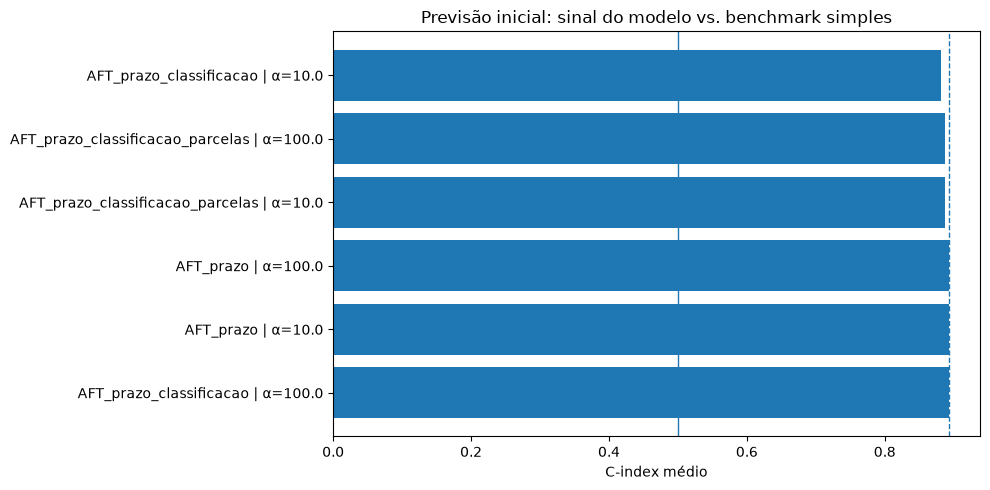

In [33]:
plot_resumo = (
    resumo.copy()
)

plot_resumo["rotulo"] = (
    plot_resumo["modelo"]
    + " | α="
    + plot_resumo[
        "alpha"
    ].astype(str)
)

plt.figure(
    figsize=(10, 5)
)

plt.barh(
    plot_resumo[
        "rotulo"
    ],
    plot_resumo[
        "cindex_medio"
    ],
)

plt.axvline(
    0.5,
    linewidth=1,
)

plt.axvline(
    baseline_mean,
    linewidth=1,
    linestyle="--",
)

plt.xlabel(
    "C-index médio"
)

plt.title(
    "Previsão inicial: sinal do modelo vs. benchmark simples"
)

plt.tight_layout()
plt.show()

## 16. Ajustar o modelo final

Para o modelo atual, usamos todos os contratos aptos:

- concluídos;
- em andamento censurados.

O suspenso/paralisado permanece no dataset, mas não participa do ajuste principal.

In [34]:
config = CANDIDATOS[
    BEST_MODEL
]

BEST_NUMERIC = (
    config["numericas"]
)

BEST_CATEGORICAL = (
    config["categoricas"]
)

BEST_FEATURES = (
    BEST_NUMERIC
    + BEST_CATEGORICAL
)

modelagem = df[
    df[
        "flag_apto_modelo_survival"
    ].eq(1)
].copy()

prep_final = (
    criar_preprocessador(
        BEST_NUMERIC,
        BEST_CATEGORICAL,
    )
)

X_final = (
    prep_final
    .fit_transform(
        modelagem[
            BEST_FEATURES
        ]
    )
)

modelo_final = (
    LogNormalAFT(
        alpha=BEST_ALPHA
    )
)

modelo_final.fit(
    X_final,
    modelagem[
        "tempo_observado_dias"
    ],
    modelagem[
        "evento_conclusao"
    ],
)

print(
    "Contratos usados no modelo final:",
    len(modelagem),
)

print(
    "Eventos:",
    int(
        modelagem[
            "evento_conclusao"
        ].sum()
    ),
)

print(
    "Censurados:",
    int(
        modelagem[
            "evento_conclusao"
        ].eq(0).sum()
    ),
)

print(
    "Convergência:",
    modelo_final.resultado_.success,
)

Contratos usados no modelo final: 63
Eventos: 50
Censurados: 13
Convergência: True


## 17. Previsão para contratos em andamento

A previsão mais útil agora é:

> qual a probabilidade de este contrato ultrapassar o prazo vigente, dado que ele ainda não terminou até hoje?

Essa é uma probabilidade **condicional ao tempo já observado**.

In [35]:
andamento = df[
    df[
        "grupo_modelagem"
    ].eq(
        "EM_ANDAMENTO_CENSURADO"
    )
].copy()

X_andamento = (
    prep_final
    .transform(
        andamento[
            BEST_FEATURES
        ]
    )
)

andamento[
    "prob_ultrapassar_prazo"
] = (
    modelo_final
    .prob_atraso_condicional(
        X_andamento,
        andamento[
            "tempo_observado_dias"
        ].to_numpy(),
        andamento[
            "prazo_vigente_observado_dias"
        ].to_numpy(),
    )
)

andamento[
    "duracao_mediana_modelo_dias"
] = (
    modelo_final
    .mediana_tempo(
        X_andamento
    )
)

previsoes_andamento = (
    andamento[
        [
            "id_contrato",
            "classificacao_contrato",
            "data_os",
            "data_termino_vigente_observada",
            "tempo_observado_dias",
            "prob_ultrapassar_prazo",
            "duracao_mediana_modelo_dias",
        ]
    ]
    .sort_values(
        "prob_ultrapassar_prazo",
        ascending=False,
    )
)

display(
    previsoes_andamento.round(3)
)

,id_contrato,classificacao_contrato,data_os,data_termino_vigente_observada,tempo_observado_dias,prob_ultrapassar_prazo,duracao_mediana_modelo_dias
51,376,Reforma Global,2025-04-22,2026-09-07,540,1.000,504.403
60,405,Reforma Parcial,2025-08-27,2026-02-23,413,1.000,283.856
57,392,Reforma Parcial,2025-10-17,2027-04-10,362,0.786,706.450
48,340,Reforma Global e Ampliação,2025-05-28,2027-05-18,504,0.766,897.338
56,391,Construção,2025-10-01,2027-05-24,378,0.762,771.115
41,275,Construção,2024-05-20,2027-07-14,877,0.722,1257.266
63,418,Reforma Global e Ampliação,2026-07-14,2028-05-04,92,0.720,834.706
58,398,Construção,2025-11-28,2027-12-18,320,0.675,897.338
55,390,Construção,2025-11-04,2028-10-19,344,0.647,1257.266
62,416,Construção,2026-03-20,2029-03-04,208,0.647,1257.266


In [36]:
# ============================================================
# REGRESSÃO DIRETA DO ATRASO
# TweedieRegressor
# ============================================================

# O Tweedie é interessante aqui porque:
#
# - target_atraso_dias >= 0
# - muitos contratos possuem atraso = 0
# - existem alguns atrasos muito altos
#
# Diferente do modelo AFT, esta regressão só pode usar
# contratos cujo atraso final já é conhecido.

REG_NUMERIC_FEATURES = [
    "log_prazo_original",
    "log_qtd_parcelas_originais",
]

REG_CATEGORICAL_FEATURES = [
    "classificacao_contrato",
]

REG_FEATURES = (
    REG_NUMERIC_FEATURES
    + REG_CATEGORICAL_FEATURES
)

print("Features da regressão:")
print(REG_FEATURES)

Features da regressão:
['log_prazo_original', 'log_qtd_parcelas_originais', 'classificacao_contrato']


In [37]:
# ============================================================
# PIPELINE DO MODELO DE REGRESSÃO
# ============================================================

def criar_tweedie(alpha=1.0, power=1.5):

    preprocessador = criar_preprocessador(
        REG_NUMERIC_FEATURES,
        REG_CATEGORICAL_FEATURES,
    )

    modelo = TweedieRegressor(
        power=power,

        # link log garante previsões positivas
        link="log",

        # regularização
        alpha=alpha,

        max_iter=5000,
    )

    return Pipeline([
        (
            "preprocessamento",
            preprocessador,
        ),
        (
            "modelo",
            modelo,
        ),
    ])

# Parte C — Como explicar a viabilidade para um colega

## 18. O que já podemos afirmar

O modelo inicial é factível se conseguirmos demonstrar:

1. **Target correto:** contratos em andamento entram como censurados, não como falsos negativos.
2. **Sinal acima do acaso:** C-index acima de 0,50 na validação temporal.
3. **Benchmark explícito:** sabemos quanto do desempenho vem apenas do prazo original.
4. **Previsão utilizável agora:** contratos em andamento podem ser ordenados por risco de ultrapassar o prazo.
5. **Caminho claro de melhoria:** a base continuará ganhando eventos e features temporais.

A conclusão deve ser proporcional às métricas observadas.

Se o AFT superar pouco o benchmark, a mensagem correta não é "o modelo está excelente". A mensagem é:

> o problema já pode ser modelado de forma estatisticamente correta; o próximo ganho precisa vir de mais desfechos observados e sinais da execução, não de um algoritmo mais complexo.

In [38]:
cindex_modelo = float(
    escolhido[
        "cindex_medio"
    ]
)

delta_baseline = (
    cindex_modelo
    - baseline_mean
)

print("=" * 78)
print("RESUMO PARA APRESENTAÇÃO")
print("=" * 78)

print(
    f"1. Base preservada: {len(df)} contratos."
)

print(
    f"2. Conclusões observadas: {n_concluidos}."
)

print(
    f"3. Em andamento censurados: {n_andamento}."
)

print(
    f"4. Suspensos/paralisados separados: {n_suspensos}."
)

print(
    f"5. C-index médio do modelo escolhido: {cindex_modelo:.3f}."
)

print(
    f"6. C-index do benchmark de prazo: {baseline_mean:.3f}."
)

print(
    f"7. Ganho sobre benchmark: {delta_baseline:+.3f}."
)

print(
    f"8. Potencial de crescimento dos eventos: +{crescimento_potencial:.1f}%."
)

if cindex_modelo > 0.50:
    print(
        "9. Há sinal preditivo acima do acaso na validação temporal."
    )
else:
    print(
        "9. Ainda não há evidência de sinal acima do acaso."
    )

if delta_baseline >= 0.02:
    print(
        "10. As features adicionais agregam ganho material sobre o prazo isolado."
    )
else:
    print(
        "10. O ganho além do prazo ainda é pequeno; a próxima melhoria deve vir dos dados."
    )

RESUMO PARA APRESENTAÇÃO
1. Base preservada: 64 contratos.
2. Conclusões observadas: 50.
3. Em andamento censurados: 13.
4. Suspensos/paralisados separados: 1.
5. C-index médio do modelo escolhido: 0.893.
6. C-index do benchmark de prazo: 0.893.
7. Ganho sobre benchmark: +0.000.
8. Potencial de crescimento dos eventos: +26.0%.
9. Há sinal preditivo acima do acaso na validação temporal.
10. O ganho além do prazo ainda é pequeno; a próxima melhoria deve vir dos dados.


In [39]:
# ============================================================
# MÉTRICAS DA REGRESSÃO
# ============================================================

def metricas_regressao(
    y_real,
    y_previsto,
):

    y_real = np.asarray(
        y_real,
        dtype=float,
    )

    y_previsto = np.maximum(
        np.asarray(
            y_previsto,
            dtype=float,
        ),
        1e-6,
    )

    erro = (
        y_previsto
        - y_real
    )

    return {
        "mae": mean_absolute_error(
            y_real,
            y_previsto,
        ),

        "rmse": np.sqrt(
            mean_squared_error(
                y_real,
                y_previsto,
            )
        ),

        "r2": r2_score(
            y_real,
            y_previsto,
        ),

        "erro_assinado_medio": (
            erro.mean()
        ),

        "spearman": (
            spearmanr(
                y_real,
                y_previsto,
            ).statistic
            if len(
                np.unique(
                    y_previsto
                )
            ) > 1
            else np.nan
        ),

        "tweedie_deviance": (
            mean_tweedie_deviance(
                y_real,
                y_previsto,
                power=1.5,
            )
        ),
    }

In [40]:
# ============================================================
# VALIDAÇÃO TEMPORAL DA REGRESSÃO
# ============================================================

ALPHAS_TWEEDIE = [
    0.1,
    1.0,
    10.0,
    100.0,
]

resultados_regressao = []


for fold_id, fold in enumerate(
    folds,
    start=1,
):

    # --------------------------------------------------------
    # TREINO
    # --------------------------------------------------------

    train = fold["train"].copy()

    # A regressão só pode usar contratos cujo desfecho
    # já era conhecido até a data daquele fold.
    train_reg = train[
        train["evento_fold"].eq(1)
        & train[
            "target_atraso_dias"
        ].notna()
    ].copy()


    # --------------------------------------------------------
    # VALIDAÇÃO
    # --------------------------------------------------------

    val = fold["val"].copy()

    # Para calcular métricas precisamos conhecer o
    # atraso final real.
    val_reg = val[
        val[
            "target_atraso_dias"
        ].notna()
    ].copy()


    if len(val_reg) < 2:
        print(
            f"Fold {fold_id}: poucos contratos "
            "com target conhecido."
        )

        continue


    X_train = train_reg[
        REG_FEATURES
    ]

    y_train = train_reg[
        "target_atraso_dias"
    ].astype(float)


    X_val = val_reg[
        REG_FEATURES
    ]

    y_val = val_reg[
        "target_atraso_dias"
    ].astype(float)


    # --------------------------------------------------------
    # BASELINE
    # --------------------------------------------------------

    dummy = DummyRegressor(
        strategy="median"
    )

    dummy.fit(
        X_train,
        y_train,
    )

    pred_dummy = dummy.predict(
        X_val
    )

    resultados_regressao.append({
        "fold": fold_id,
        "modelo": "Dummy mediana",
        "alpha": np.nan,
        "contratos_treino": len(
            train_reg
        ),
        "contratos_validacao": len(
            val_reg
        ),
        **metricas_regressao(
            y_val,
            np.maximum(
                pred_dummy,
                1e-6,
            ),
        ),
    })


    # --------------------------------------------------------
    # TWEEDIE
    # --------------------------------------------------------

    for alpha in ALPHAS_TWEEDIE:

        modelo = criar_tweedie(
            alpha=alpha,
            power=1.5,
        )

        modelo.fit(
            X_train,
            y_train,
        )

        pred = modelo.predict(
            X_val
        )

        pred = np.maximum(
            pred,
            0,
        )

        resultados_regressao.append({
            "fold": fold_id,
            "modelo": "Tweedie",
            "alpha": alpha,
            "contratos_treino": len(
                train_reg
            ),
            "contratos_validacao": len(
                val_reg
            ),
            **metricas_regressao(
                y_val,
                pred,
            ),
        })


resultado_reg_cv = pd.DataFrame(
    resultados_regressao
)

display(
    resultado_reg_cv.round(3)
)

,fold,modelo,alpha,contratos_treino,contratos_validacao,mae,rmse,r2,erro_assinado_medio,spearman,tweedie_deviance
0,1,Dummy mediana,NaN,23,7,18.286,32.501,-0.463,-18.286,NaN,73121.615
1,1,Tweedie,0.1,23,7,30.439,36.785,-0.874,10.299,0.217,22.553
2,1,Tweedie,1.0,23,7,28.262,33.967,-0.598,10.243,0.217,16.218
3,1,Tweedie,10.0,23,7,29.702,32.977,-0.506,14.231,0.079,15.187
4,1,Tweedie,100.0,23,7,30.522,32.931,-0.502,18.229,0.079,15.158
5,2,Dummy mediana,NaN,28,6,9.833,11.839,-0.025,-1.833,NaN,9.789
6,2,Tweedie,0.1,28,6,39.958,46.745,-14.973,39.958,-0.257,19.589
7,2,Tweedie,1.0,28,6,33.976,37.044,-9.030,33.976,-0.394,18.086
8,2,Tweedie,10.0,28,6,34.469,36.779,-8.888,34.469,-0.394,18.114
9,2,Tweedie,100.0,28,6,36.051,37.954,-9.530,36.051,-0.394,18.441


In [41]:
# ============================================================
# RESUMO DA VALIDAÇÃO TEMPORAL
# ============================================================

resumo_reg = (
    resultado_reg_cv
    .groupby(
        [
            "modelo",
            "alpha",
        ],
        dropna=False,
        as_index=False,
    )
    .agg(
        mae_medio=(
            "mae",
            "mean",
        ),

        mae_dp=(
            "mae",
            "std",
        ),

        rmse_medio=(
            "rmse",
            "mean",
        ),

        r2_medio=(
            "r2",
            "mean",
        ),

        spearman_medio=(
            "spearman",
            "mean",
        ),

        erro_assinado_medio=(
            "erro_assinado_medio",
            "mean",
        ),

        folds=(
            "fold",
            "count",
        ),
    )
    .sort_values(
        [
            "mae_medio",
            "rmse_medio",
        ]
    )
)

display(
    resumo_reg.round(3)
)

,modelo,alpha,mae_medio,mae_dp,rmse_medio,r2_medio,spearman_medio,erro_assinado_medio,folds
0,Dummy mediana,NaN,23.817,24.405,35.987,-0.491,NaN,-21.817,4
2,Tweedie,1.0,37.777,14.588,42.943,-4.816,0.094,11.107,4
3,Tweedie,10.0,38.831,14.044,43.136,-5.146,-0.161,13.035,4
1,Tweedie,0.1,39.423,12.114,46.374,-7.120,0.128,12.993,4
4,Tweedie,100.0,39.783,13.495,43.590,-5.537,-0.161,15.138,4


In [42]:
# ============================================================
# SELEÇÃO DO MELHOR TWEEDIE
# ============================================================

tweedie_resumo = (
    resumo_reg[
        resumo_reg[
            "modelo"
        ].eq(
            "Tweedie"
        )
    ]
    .sort_values(
        [
            "mae_medio",
            "rmse_medio",
        ]
    )
)

BEST_TWEEDIE_ALPHA = float(
    tweedie_resumo
    .iloc[0][
        "alpha"
    ]
)

print(
    "Melhor alpha Tweedie:",
    BEST_TWEEDIE_ALPHA,
)

display(
    tweedie_resumo.round(3)
)

Melhor alpha Tweedie: 1.0


,modelo,alpha,mae_medio,mae_dp,rmse_medio,r2_medio,spearman_medio,erro_assinado_medio,folds
2,Tweedie,1.0,37.777,14.588,42.943,-4.816,0.094,11.107,4
3,Tweedie,10.0,38.831,14.044,43.136,-5.146,-0.161,13.035,4
1,Tweedie,0.1,39.423,12.114,46.374,-7.120,0.128,12.993,4
4,Tweedie,100.0,39.783,13.495,43.590,-5.537,-0.161,15.138,4


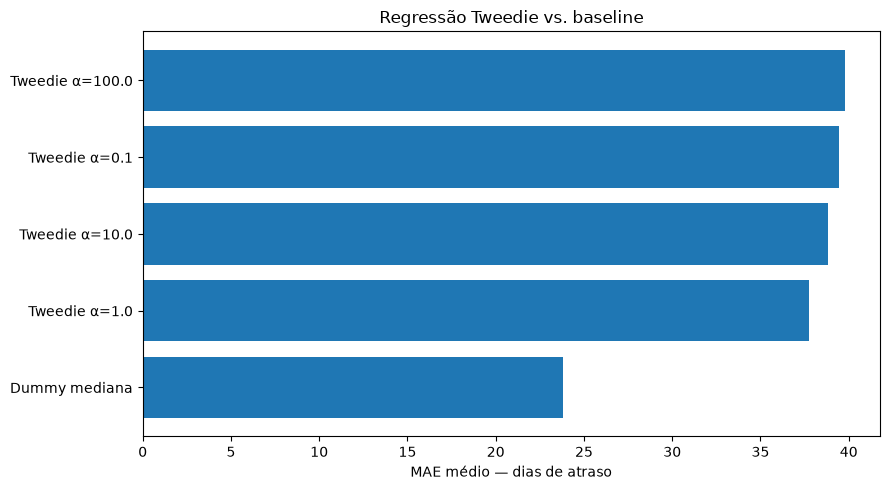

In [43]:
# ============================================================
# COMPARAÇÃO VISUAL
# ============================================================

plot_reg = resumo_reg.copy()

plot_reg["rotulo"] = np.where(
    plot_reg[
        "modelo"
    ].eq(
        "Tweedie"
    ),

    (
        "Tweedie α="
        + plot_reg[
            "alpha"
        ].astype(str)
    ),

    plot_reg["modelo"],
)

plt.figure(
    figsize=(9, 5)
)

plt.barh(
    plot_reg[
        "rotulo"
    ],
    plot_reg[
        "mae_medio"
    ],
)

plt.xlabel(
    "MAE médio — dias de atraso"
)

plt.title(
    "Regressão Tweedie vs. baseline"
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# MODELO TWEEDIE FINAL
# ============================================================

concluidos_reg = df[
    df[
        "grupo_modelagem"
    ].eq(
        "CONCLUIDO_COM_TARGET"
    )
    & df[
        "target_atraso_dias"
    ].notna()
].copy()


modelo_tweedie_final = criar_tweedie(
    alpha=BEST_TWEEDIE_ALPHA,
    power=1.5,
)


modelo_tweedie_final.fit(
    concluidos_reg[
        REG_FEATURES
    ],
    concluidos_reg[
        "target_atraso_dias"
    ].astype(float),
)


print(
    "Contratos usados:",
    len(concluidos_reg),
)

print(
    "Contratos com atraso:",
    int(
        (
            concluidos_reg[
                "target_atraso_dias"
            ]
            > 0
        ).sum()
    ),
)

print(
    "Contratos sem atraso:",
    int(
        (
            concluidos_reg[
                "target_atraso_dias"
            ]
            == 0
        ).sum()
    ),
)

Contratos usados: 50
Contratos com atraso: 21
Contratos sem atraso: 29


In [45]:
concluidos_reg[
    "pred_atraso_tweedie"
] = np.maximum(
    0,
    modelo_tweedie_final.predict(
        concluidos_reg[
            REG_FEATURES
        ]
    ),
)

comparacao_tweedie = (
    concluidos_reg[
        [
            "id_contrato",
            "prazo_original_dias",
            "target_atraso_dias",
            "pred_atraso_tweedie",
        ]
    ]
    .copy()
)

comparacao_tweedie[
    "erro_dias"
] = (
    comparacao_tweedie[
        "pred_atraso_tweedie"
    ]
    - comparacao_tweedie[
        "target_atraso_dias"
    ]
)

display(
    comparacao_tweedie.round(1)
)

,id_contrato,prazo_original_dias,target_atraso_dias,pred_atraso_tweedie,erro_dias
0,11,150,25.0,29.7,4.7
1,12,90,139.0,125.5,-13.5
2,18,120,0.0,30.4,30.4
3,29,240,106.0,36.6,-69.4
4,30,90,0.0,31.4,31.4
5,31,120,30.0,30.4,0.4
6,32,90,0.0,31.4,31.4
7,33,660,0.0,24.4,24.4
8,46,180,28.0,37.4,9.4
9,47,180,12.0,29.1,17.1


## 19. Por que esperamos melhorar

A melhoria futura não depende de uma promessa abstrata.

Ela vem de mudanças concretas na informação disponível:

### A. Mais eventos observados

Cada contrato em andamento que concluir deixa de ser censurado e passa a informar a duração real.

### B. Mais diversidade

Os contratos novos ampliam a presença de construções e outras classificações, reduzindo a concentração histórica em reformas parciais.

### C. Features de execução

O dataset já preserva:

- aditivos observados;
- parcelas concluídas;
- liberações observadas.

Esses sinais não entram no modelo inicial porque precisam ser usados com uma data de corte histórica correta.

A próxima versão pode adotar **landmarks**, por exemplo:

- previsão na OS;
- atualização 180 dias antes do prazo;
- atualização 90 dias antes;
- atualização 60 dias antes.

Assim, a previsão inicial vira a primeira camada de um sistema de risco que é atualizado durante a execução.

## 20. Exportar dataset e resultados

In [46]:
DATASET_PATH = (
    OUTPUT_DIR
    / "dataset_64_contratos_tres_grupos.csv"
)

CV_PATH = (
    OUTPUT_DIR
    / "validacao_temporal_previsao_inicial.csv"
)

RESUMO_PATH = (
    OUTPUT_DIR
    / "resumo_modelos_previsao_inicial.csv"
)

BASELINE_PATH = (
    OUTPUT_DIR
    / "benchmark_prazo.csv"
)

PREVISOES_PATH = (
    OUTPUT_DIR
    / "previsoes_contratos_em_andamento.csv"
)

df.to_csv(
    DATASET_PATH,
    index=False,
    encoding="utf-8-sig",
)

cv.to_csv(
    CV_PATH,
    index=False,
    encoding="utf-8-sig",
)

resumo.to_csv(
    RESUMO_PATH,
    index=False,
    encoding="utf-8-sig",
)

baseline_cv.to_csv(
    BASELINE_PATH,
    index=False,
    encoding="utf-8-sig",
)

previsoes_andamento.to_csv(
    PREVISOES_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Arquivos gerados:")
print("-", DATASET_PATH)
print("-", CV_PATH)
print("-", RESUMO_PATH)
print("-", BASELINE_PATH)
print("-", PREVISOES_PATH)

Arquivos gerados:
- \mnt\data\12_base_64_outputs\dataset_64_contratos_tres_grupos.csv
- \mnt\data\12_base_64_outputs\validacao_temporal_previsao_inicial.csv
- \mnt\data\12_base_64_outputs\resumo_modelos_previsao_inicial.csv
- \mnt\data\12_base_64_outputs\benchmark_prazo.csv
- \mnt\data\12_base_64_outputs\previsoes_contratos_em_andamento.csv


# Conclusão

A proposta deste notebook é deliberadamente conservadora:

- não descartamos contratos apenas porque ainda não terminaram;
- não inventamos targets para contratos em andamento;
- não misturamos suspensão/paralisação com o processo normal de conclusão;
- não usamos informações futuras para justificar uma previsão inicial;
- comparamos o modelo com um benchmark simples;
- preferimos um modelo simples quando a diferença de desempenho é pequena.

Isso cria uma base mais confiável para evolução.

**A previsão inicial é o ponto de partida, não o produto final.**

O ganho futuro deve vir principalmente de:
1. mais contratos concluídos;
2. atualização temporal das previsões;
3. features de execução point-in-time;
4. recalibração periódica do modelo.